# 03 · One-stage anchor-based detector: RetinaNet

Same protocol, code path and evaluator as Faster R-CNN (notebook 02); only the model config changes.

Experiments (incremental): **R0** torchvision defaults → **R1** anchors fitted to the training boxes → **R2** lower IoU thresholds for positive/negative anchors → **R3** focal-loss γ/α (loss modification). Optional **R4**: box loss GIoU → L1 ablation.

## 1. Setup and protocol

In [3]:
import json
import shutil
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

SOURCE = Path("/kaggle/input/datasets")
OUT_DIR = Path("/kaggle/working")
RUN_DIR = OUT_DIR / "runs" / "retina_r3_focal"

assert SOURCE.exists(), "Dataset retinanet-resume not found"

RUN_DIR.mkdir(parents=True, exist_ok=True)

# Restore checkpoint and experiment files
for name in ["last.pth", "config.json", "history.json"]:
    matches = list(SOURCE.rglob(name))
    assert matches, f"Missing {name}"
    shutil.copy2(matches[0], RUN_DIR / name)

# Restore the original sequence folds
folds = next(
    (p for p in SOURCE.rglob("*.csv")
     if p.name.startswith("folds")),
    None
)
assert folds is not None, "folds.csv not found"
shutil.copy2(folds, OUT_DIR / "folds.csv")

# Clone the actual GitHub repository
REPO = OUT_DIR / "repo"
if not REPO.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/dd8ria/ai-hw2.git",
            str(REPO)
        ],
        check=True
    )

assert (REPO / "src" / "tvdet.py").exists()

print("Checkpoint restored:", (RUN_DIR / "last.pth").exists())
print("Folds ready:", (OUT_DIR / "folds.csv").exists())
print("Repository ready:", (REPO / "src" / "tvdet.py").exists())


Cloning into '/kaggle/working/repo'...


Checkpoint restored: True
Folds ready: True
Repository ready: True


In [4]:
import os, sys, json, shutil
from pathlib import Path

REPO = Path("/kaggle/working/repo") if Path("/kaggle").exists() else Path("..").resolve()
if Path("/kaggle").exists() and not REPO.exists():
    !git clone https://github.com/dd8ria/ai-hw2.git {REPO}
    !pip install -q faster-coco-eval
sys.path.insert(0, str(REPO / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.patches as patches, cv2
import vdet, parallel, tvdet
import torch
from vdet import CLASSES

vdet.seed_everything()
ROOT = vdet.find_data_root()
OUT = Path("/kaggle/working") if Path("/kaggle").exists() else REPO / "outputs"
RUNS = OUT / "runs"; RUNS.mkdir(parents=True, exist_ok=True)
RESULT_DIRS = [RUNS, REPO / "results"]   # own runs + runs committed by the teammate
P = vdet.PROTOCOL

# restore finished runs from earlier versions of this notebook (attached as Kaggle input)
for src in (Path("/kaggle/input").glob("*/runs/*") if Path("/kaggle/input").exists() else []):
    if (src / "config.json").exists() and not (RUNS / src.name).exists():
        shutil.copytree(src, RUNS / src.name); print("restored", src.name)

In [5]:
imgs, anns = vdet.load_all(ROOT)
folds = pd.read_csv(OUT / "folds.csv") if (OUT / "folds.csv").exists() else vdet.make_folds(imgs, P["n_folds"])
folds.to_csv(OUT / "folds.csv", index=False)   # the parallel runner reads the split from this file
train_frames, val_frames = vdet.protocol_frames(imgs, folds, P)
train_gt = anns[anns.key.isin(train_frames.key) & (anns.iscrowd == 0)]
print(json.dumps(P))
print(f"train: {len(train_frames)} frames | val: {len(val_frames)} frames / {val_frames.clip_uid.nunique()} clips")

{"val_fold": 0, "n_folds": 5, "step": 10, "val_step": 10, "imgsz": 1280, "epochs": 12, "seed": 42}
train: 2189 frames | val: 545 frames / 12 clips


## 2. Grounding anchors in the data

Anchors are fitted on the **training folds only** (learned preprocessing must not see the holdout). For each candidate anchor set we compute *coverage*: the share of training boxes (rescaled to `imgsz`) whose best anchor has shape-IoU ≥ 0.5 (RetinaNet's positive threshold) or ≥ 0.4. Shape-IoU ignores the position on the stride grid, so real coverage is somewhat lower, mostly for the tiniest boxes.

In [6]:
sc = (P["imgsz"] / np.maximum(train_gt.width, train_gt.height)).values  # long side -> imgsz, as in training
wh = np.c_[train_gt.w.values * sc, train_gt.h.values * sc]

def anchor_set(base_sizes, ratios, octaves=3):
    out = []
    for s in base_sizes:
        for o in range(octaves):
            a = s * 2 ** (o / octaves)
            for r in ratios:  # torchvision: ratio = h / w
                out.append((a / np.sqrt(r), a * np.sqrt(r)))
    return np.array(out)

def coverage(wh, anchors):
    inter = np.minimum(wh[:, None, 0], anchors[None, :, 0]) * np.minimum(wh[:, None, 1], anchors[None, :, 1])
    iou = inter / (wh[:, None].prod(2) + anchors[None].prod(2) - inter)
    best = iou.max(1)
    return {"cov@0.5": (best >= .5).mean(), "cov@0.4": (best >= .4).mean(), "mean best IoU": best.mean()}

rng = np.random.default_rng(0); whs = wh[rng.choice(len(wh), min(100_000, len(wh)), replace=False)]
print("box side at imgsz: p5 / median / p95 =", np.round(np.quantile(np.sqrt(whs.prod(1)), [.05, .5, .95]), 1))
print("h/w ratio quantiles p10/p50/p90 =", np.round(np.quantile(whs[:, 1] / whs[:, 0], [.1, .5, .9]), 2))

DEFAULT = dict(base=[32, 64, 128, 256, 512], ratios=[0.5, 1.0, 2.0])
rows = [{"base": "default 32..512", "ratios": str(DEFAULT["ratios"]), **coverage(whs, anchor_set(DEFAULT["base"], DEFAULT["ratios"]))}]
for s0 in [8, 12, 16, 24]:
    for ratios in ([0.5, 1.0, 2.0], [0.5, 1.0, 2.0, 3.0], [0.33, 0.66, 1.0, 1.5, 3.0]):
        base = [s0 * 2 ** i for i in range(5)]
        rows.append({"base": f"{s0}..{base[-1]}", "s0": s0, "ratios": str(ratios), "n_ratios": len(ratios),
                     **coverage(whs, anchor_set(base, ratios))})
cov = pd.DataFrame(rows)
display(cov.style.format("{:.3f}", subset=["cov@0.5", "cov@0.4", "mean best IoU"]))

box side at imgsz: p5 / median / p95 = [13.6 30.4 79.9]
h/w ratio quantiles p10/p50/p90 = [0.48 1.06 2.26]


,base,ratios,cov@0.5,cov@0.4,mean best IoU,s0,n_ratios
0,default 32..512,"[0.5, 1.0, 2.0]",0.718,0.788,0.648,nan,nan
1,8..128,"[0.5, 1.0, 2.0]",0.999,1.000,0.829,8.000000,3.000000
2,8..128,"[0.5, 1.0, 2.0, 3.0]",0.999,1.000,0.837,8.000000,4.000000
3,8..128,"[0.33, 0.66, 1.0, 1.5, 3.0]",0.999,1.000,0.842,8.000000,5.000000
4,12..192,"[0.5, 1.0, 2.0]",0.996,0.998,0.825,12.000000,3.000000
5,12..192,"[0.5, 1.0, 2.0, 3.0]",0.996,0.998,0.833,12.000000,4.000000
6,12..192,"[0.33, 0.66, 1.0, 1.5, 3.0]",0.996,0.998,0.839,12.000000,5.000000
7,16..256,"[0.5, 1.0, 2.0]",0.982,0.990,0.813,16.000000,3.000000
8,16..256,"[0.5, 1.0, 2.0, 3.0]",0.982,0.990,0.821,16.000000,4.000000
9,16..256,"[0.33, 0.66, 1.0, 1.5, 3.0]",0.982,0.990,0.825,16.000000,5.000000


In [7]:
# Pick the best set by coverage@0.5; prefer 3 ratios when the gain from more ratios is < 1 pt,
# because every extra ratio adds a full set of anchors (memory, more negatives).
cand = cov.dropna(subset=["s0"]).sort_values("cov@0.5", ascending=False)
best3 = cand[cand.n_ratios == 3].iloc[0]; best_any = cand.iloc[0]
chosen = best_any if best_any["cov@0.5"] - best3["cov@0.5"] >= 0.01 else best3
ANCHOR_SIZES = [int(chosen.s0) * 2 ** i for i in range(5)]
ASPECT_RATIOS = json.loads(chosen.ratios)
print("chosen anchors:", ANCHOR_SIZES, ASPECT_RATIOS, f"cov@0.5={chosen['cov@0.5']:.3f}")

chosen anchors: [8, 16, 32, 64, 128] [0.5, 1.0, 2.0] cov@0.5=0.999


## 3. Experiments

In [8]:
BASE = dict(arch="retinanet_v2", imgsz=P["imgsz"], epochs=P["epochs"], batch=4, lr=0.01, sched="step",
            box_loss="giou", focal_gamma=2.0, focal_alpha=0.25, seed=P["seed"])
EXPERIMENTS = {"retina_r0_base": BASE}
EXPERIMENTS["retina_r1_anchors"] = {**BASE, "anchor_sizes": ANCHOR_SIZES, "aspect_ratios": ASPECT_RATIOS}
# small boxes rarely reach IoU 0.5 with any anchor -> lower thresholds give them positives
EXPERIMENTS["retina_r2_iou"] = {**EXPERIMENTS["retina_r1_anchors"], "kwargs": dict(fg_iou_thresh=0.4, bg_iou_thresh=0.3)}
FOCAL_ON = "retina_r2_iou"   # set to the better of r1/r2 once both finished
EXPERIMENTS["retina_r3_focal"] = {**EXPERIMENTS[FOCAL_ON], "focal_gamma": 1.5, "focal_alpha": 0.25}
EXPERIMENTS["retina_r4_l1"] = {**EXPERIMENTS[FOCAL_ON], "box_loss": "l1"}
pd.DataFrame(EXPERIMENTS).T[["anchor_sizes", "aspect_ratios", "kwargs", "focal_gamma", "box_loss"]]

,anchor_sizes,aspect_ratios,kwargs,focal_gamma,box_loss
retina_r0_base,NaN,NaN,NaN,2.0,giou
retina_r1_anchors,"[8, 16, 32, 64, 128]","[0.5, 1.0, 2.0]",NaN,2.0,giou
retina_r2_iou,"[8, 16, 32, 64, 128]","[0.5, 1.0, 2.0]","{'fg_iou_thresh': 0.4, 'bg_iou_thresh': 0.3}",2.0,giou
retina_r3_focal,"[8, 16, 32, 64, 128]","[0.5, 1.0, 2.0]","{'fg_iou_thresh': 0.4, 'bg_iou_thresh': 0.3}",1.5,giou
retina_r4_l1,"[8, 16, 32, 64, 128]","[0.5, 1.0, 2.0]","{'fg_iou_thresh': 0.4, 'bg_iou_thresh': 0.3}",2.0,l1


In [9]:
# Accelerator "GPU T4 x2": two runs train at the same time, one per GPU (quota is per session hour).
# Queue as many runs as fit into the 12 h session; finished runs are skipped. Logs: runs/<name>.log
RUN = [
    "retina_r3_focal",
    "retina_r4_l1"
]
codes = parallel.run_parallel([(n, EXPERIMENTS[n]) for n in RUN], RUNS, folds_csv=OUT / "folds.csv")

2 jobs on GPUs [0, 1]
[   0.0 min] started retina_r3_focal on GPU 0
[   0.0 min] started retina_r4_l1 on GPU 1
[   0.5 min] retina_r3_focal (GPU 0):   print(f"ep {ep} it {it}/{len(dl)} loss {float(loss):.3f} lr {opt.param_groups[0]['lr']:.5f}")
[   0.5 min] retina_r4_l1 (GPU 1):   print(f"ep {ep} it {it}/{len(dl)} loss {float(loss):.3f} lr {opt.param_groups[0]['lr']:.5f}")
[  10.5 min] retina_r3_focal (GPU 0): epoch 6: AP 0.1425 AP50 0.3630 AP_s 0.0657 (5.6 min)
[  10.5 min] retina_r4_l1 (GPU 1): epoch 1: AP 0.0464 AP50 0.1558 AP_s 0.0312 (5.3 min)
[  20.5 min] retina_r3_focal (GPU 0): epoch 7: AP 0.1537 AP50 0.3787 AP_s 0.0705 (5.6 min)
[  20.5 min] retina_r4_l1 (GPU 1): epoch 2: AP 0.1029 AP50 0.2727 AP_s 0.0538 (5.2 min)
[  30.5 min] retina_r3_focal (GPU 0): ep 8 it 500/547 loss 0.510 lr 0.00100
[  30.5 min] retina_r4_l1 (GPU 1): ep 3 it 500/547 loss 0.679 lr 0.01000
[  40.5 min] retina_r3_focal (GPU 0): ep 9 it 500/547 loss 0.385 lr 0.00100
[  40.5 min] retina_r4_l1 (GPU 1): epoch 

In [15]:

from pathlib import Path
from zipfile import ZipFile, ZIP_STORED

root = Path("/kaggle/working")
archive = root / "retinanet_R3_R4_backup.zip"

with ZipFile(archive, "w", compression=ZIP_STORED) as z:
    for name in ["retina_r3_focal", "retina_r4_l1"]:
        folder = root / "runs" / name
        for file in folder.rglob("*"):
            if file.is_file():
                z.write(file, arcname=file.relative_to(root))

print("Backup created:", archive.exists())
print("Size (MB):", round(archive.stat().st_size / 1024**2, 1))


Backup created: True
Size (MB): 1125.6


In [13]:

from pathlib import Path
import json

print("Exit codes:", codes)

for name in ["retina_r3_focal", "retina_r4_l1"]:
    folder = Path("/kaggle/working/runs") / name
    metrics = folder / "metrics.json"

    print(f"\n{name}")
    print("Final weights:", (folder / "final.pth").exists())
    print("Metrics:", metrics.exists())

    if metrics.exists():
        m = json.loads(metrics.read_text())
        print("AP:", m.get("AP"))
        print("AP50:", m.get("AP50"))
        print("Epochs:", m.get("epochs"))


Exit codes: {'retina_r3_focal': 0, 'retina_r4_l1': 0}

retina_r3_focal
Final weights: True
Metrics: True
AP: 0.16070036285857145
AP50: 0.3876840377789623
Epochs: 12

retina_r4_l1
Final weights: True
Metrics: True
AP: 0.16169996044085228
AP50: 0.3924465208638673
Epochs: 12


## 4. Results and comparison with the tuned two-stage detector

In [1]:
# Section 4 setup only — DOES NOT train the models.
# Rebuild the expected runs/<experiment>/ structure from results committed to GitHub.
from pathlib import Path
import subprocess
import sys
import shutil
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

OUT = Path('/kaggle/working') if Path('/kaggle').exists() else Path.cwd()
REPO = OUT / 'repo'

if (REPO / '.git').exists():
    subprocess.run(['git', '-C', str(REPO), 'pull', '--ff-only'], check=True)
else:
    subprocess.run(
        ['git', 'clone', 'https://github.com/dd8ria/ai-hw2.git', str(REPO)],
        check=True,
    )

SRC = REPO / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
import vdet

RUNS = OUT / 'runs'
RUNS.mkdir(parents=True, exist_ok=True)
RESULT_DIRS = [RUNS, REPO / 'results']
GITHUB_RESULTS = REPO / 'results' / 'retinanet'
if not GITHUB_RESULTS.is_dir():
    raise FileNotFoundError(f'GitHub results directory not found: {GITHUB_RESULTS}')

NAMES = [
    'retina_r0_base',
    'retina_r1_anchors',
    'retina_r2_iou',
    'retina_r3_focal',
    'retina_r4_l1',
]
NEEDED = ['config.json', 'history.json', 'metrics.json', 'val_preds.csv.gz']

missing = []
for name in NAMES:
    dest = RUNS / name
    dest.mkdir(parents=True, exist_ok=True)
    for filename in NEEDED:
        source = GITHUB_RESULTS / f'{name}_{filename}'
        if source.exists():
            shutil.copy2(source, dest / filename)
        else:
            missing.append(source.name)
    print(name, '| metrics:', (dest / 'metrics.json').exists(),
          '| history:', (dest / 'history.json').exists())

if missing:
    raise FileNotFoundError('Missing on GitHub: ' + ', '.join(missing))
print('All five RetinaNet experiments restored. Section 4 is ready.')


Cloning into '/kaggle/working/repo'...


retina_r0_base | metrics: True | history: True
retina_r1_anchors | metrics: True | history: True
retina_r2_iou | metrics: True | history: True
retina_r3_focal | metrics: True | history: True
retina_r4_l1 | metrics: True | history: True
All five RetinaNet experiments restored. Section 4 is ready.


In [2]:
COLS = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR_max", "ms_per_img", "epochs"]
def show(res, cols=COLS):
    cols = [c for c in cols if c in res]
    num = [c for c in cols if c not in ("ms_per_img", "epochs")]
    return res[cols].style.format("{:.4f}", subset=num).format("{:.1f}", subset=[c for c in ["ms_per_img"] if c in cols])

res = vdet.collect_results(RESULT_DIRS, "retina")
frcnn = vdet.collect_results(RESULT_DIRS, "frcnn")
if len(frcnn):
    best_frcnn = frcnn.AP.idxmax(); res = pd.concat([res, frcnn.loc[[best_frcnn]]])
if len(res): display(show(res))

,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR_max,ms_per_img,epochs
run,,,,,,,,,
retina_r0_base,0.2303,0.4217,0.2190,0.0759,0.1743,0.4362,0.3785,50.7,12
retina_r1_anchors,0.1455,0.3574,0.0996,0.0687,0.1141,0.2345,0.3461,51.4,12
retina_r2_iou,0.1624,0.3828,0.1171,0.0726,0.1229,0.2607,0.3495,51.1,12
retina_r3_focal,0.1607,0.3877,0.1140,0.0734,0.1264,0.2593,0.3451,50.7,12
retina_r4_l1,0.1617,0.3924,0.1102,0.0724,0.1311,0.2597,0.3486,49.4,12
frcnn_e1_proposals,0.2561,0.4795,0.2441,0.1094,0.2032,0.4448,0.3902,114.3,12


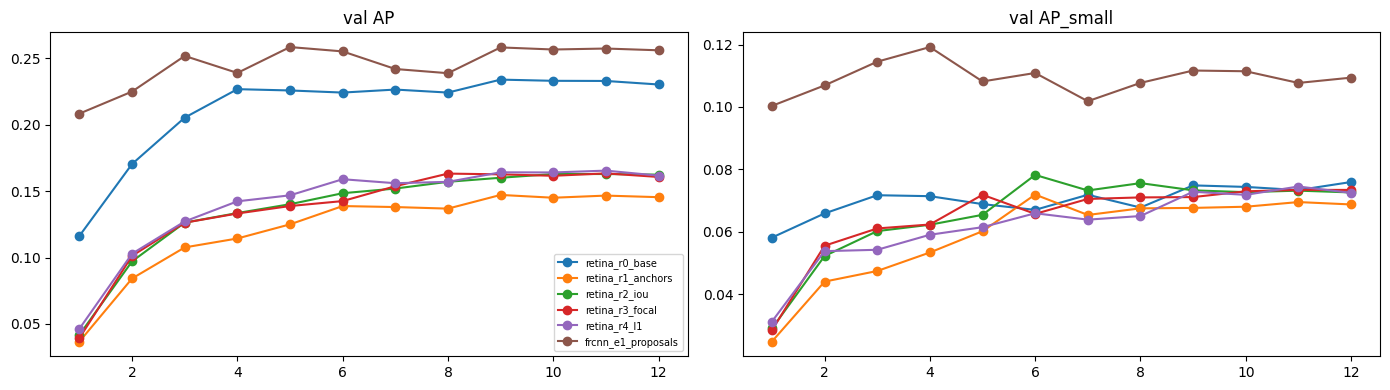

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for run in res.index if len(res) else []:
    h = vdet.load_history(RESULT_DIRS, run)
    if h is not None:
        axes[0].plot(h.epoch, h.AP, "o-", label=run); axes[1].plot(h.epoch, h.AP_small, "o-", label=run)
axes[0].set_title("val AP"); axes[1].set_title("val AP_small"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "retina_curves.png", dpi=120); plt.show()

**Does removing the proposal stage cause issues?** Fill in with the numbers above.

- *Foreground/background imbalance.* At `imgsz` = 1280 RetinaNet scores ~10⁵ anchors per image, of which only a few hundred are positive. Without an RPN filtering easy negatives, the plain cross-entropy is dominated by background. Focal loss (γ) and the prior-probability initialisation of the classification bias address it — R3 tests γ.
- *No re-pooling of features.* Faster R-CNN re-samples features for each proposal with RoIAlign and refines the box a second time; RetinaNet regresses once from a fixed anchor. For tiny objects this shows up as lower AP75 / more localisation errors — compare AP75 with the Faster R-CNN row.
- *Anchor assignment for tiny boxes.* With default 32-px anchors most boxes never reach IoU 0.5 with any anchor and get no positives at all (coverage table). Fixes: anchors from data (R1), lower IoU thresholds (R2), or adaptive assignment as in ATSS.

## 5. Export and test submission

In [4]:

import sys
import importlib
from pathlib import Path
import torch

SRC = Path("/kaggle/working/repo/src")
assert (SRC / "vdet.py").exists()
assert (SRC / "tvdet.py").exists()

sys.path.insert(0, str(SRC))
importlib.invalidate_caches()

import vdet
import tvdet

ROOT = vdet.find_data_root()
OUT = Path("/kaggle/working")
RUNS = OUT / "runs"

print("GPU:", torch.cuda.is_available())
print("Modules: OK")
print("Dataset:", ROOT)
print("R0 weights:", (RUNS / "retina_r0_base" / "best.pth").exists())


GPU: True
Modules: OK
Dataset: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
R0 weights: False


In [6]:

from pathlib import Path
import shutil

matches = [
    p for p in Path("/kaggle/input").rglob("best.pth")
    if "retina-r0-best-weights" in str(p)
]

print("Found checkpoints:", matches)
assert matches, "R0 checkpoint not found"

source = matches[0]
destination = Path("/kaggle/working/runs/retina_r0_base/best.pth")

assert source.exists(), f"Checkpoint not found: {source}"

destination.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(source, destination)

# Restore the experiment configuration from GitHub
config_source = Path(
    "/kaggle/working/repo/results/retinanet/"
    "retina_r0_base_config.json"
)
assert config_source.exists(), "R0 config not found in GitHub repository"

shutil.copy2(config_source, destination.parent / "config.json")

print("R0 weights:", destination.exists())
print("R0 config:", (destination.parent / "config.json").exists())


Found checkpoints: [PosixPath('/kaggle/input/datasets/tttanyamoroz/retina-r0-best-weights/best.pth')]
R0 weights: True
R0 config: True


In [13]:
BEST = "retina_r0_base"
model = tvdet.load_run(RUNS / BEST, weights="best.pth")
test_preds = tvdet.predict_test(model, ROOT)
test_preds.to_csv(OUT / f"test_preds_{BEST}.csv.gz", index=False)

In [ ]:
# Keep only valid object classes (0–7)
test_preds = pd.read_csv(
    OUT / "test_preds_retina_r0_base.csv.gz"
)
clean_preds = test_preds[
    test_preds["cls"].between(0, 7)
].copy()

print("Removed:", len(test_preds) - len(clean_preds))

# Create and validate the Kaggle submission
submission_path = OUT / "submission_retina_r0_base.csv"

vdet.write_submission(
    clean_preds,
    ROOT / "test_images.csv",
    submission_path
)

In [ ]:
# Results for the repo: unzip results.zip from the notebook Output into <repo>/results/ and commit.
vdet.export_results(RUNS, OUT / "results", preds_for=(BEST,))